# 06 - Business Cost and Interpretability

**Objective:** move from a statistical metric (PR-AUC) to a business decision: **above what score is it worth generating an alert?** Then, understand which features drive the predictions using SHAP.

**Final model:** LightGBM without imbalance adjustment and with raw features (conclusions from notebooks 04 and 05).

**Protocol:**
- The threshold is chosen on **validation**.
- The **test set is used for the first time here**, only once, to measure the final result with the threshold already fixed.

## Cost model assumptions
These are our own assumptions, not data from the dataset:
1. Each transaction with a score ≥ threshold generates an **alert** that is manually reviewed, with a fixed cost `REVIEW_COST` per review.
2. The review detects fraud without errors: an alert on a fraudulent transaction prevents the loss.
3. An **unalerted fraud** costs the **full amount** of the transaction.
4. An alerted non-fraud costs only the review (friction and customer loss are not modeled).

Since the review cost is uncertain, a **sensitivity analysis** is performed by varying it.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import shap

from src.validation import add_day, temporal_split
from src.evaluate import evaluate, cost_curve, best_threshold, cost_at_threshold

sns.set_theme(style="whitegrid")

## 1. Data and final model

In [2]:
df = add_day(pd.read_parquet("../data/processed/train_merged.parquet"))
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].astype("category")

train, valid, test = temporal_split(df)

DROP = ["TransactionID", "TransactionDT", "day", "isFraud"]
features = [c for c in df.columns if c not in DROP]

y_train, y_valid, y_test = train["isFraud"], valid["isFraud"], test["isFraud"]
amt_valid, amt_test = valid["TransactionAmt"].values, test["TransactionAmt"].values

In [3]:
params = dict(
    objective="binary", learning_rate=0.05, n_estimators=2000, num_leaves=64,
    colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
    random_state=42, n_jobs=-1, verbose=-1,
)
model = lgb.LGBMClassifier(**params)
model.fit(
    train[features], y_train,
    eval_set=[(valid[features], y_valid)], eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)],
)
p_valid = model.predict_proba(valid[features])[:, 1]
p_test = model.predict_proba(test[features])[:, 1]
print("Best iteration:", model.best_iteration_)

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.906486	valid_0's binary_logloss: 0.0898731
[200]	valid_0's auc: 0.91775	valid_0's binary_logloss: 0.0856414
[300]	valid_0's auc: 0.920376	valid_0's binary_logloss: 0.0843805
[400]	valid_0's auc: 0.923574	valid_0's binary_logloss: 0.0833867
[500]	valid_0's auc: 0.92428	valid_0's binary_logloss: 0.0831447
[600]	valid_0's auc: 0.925021	valid_0's binary_logloss: 0.0830404
Early stopping, best iteration is:
[559]	valid_0's auc: 0.925052	valid_0's binary_logloss: 0.082948
Best iteration: 559


## 2. Cost curve on validation
For each number of alerts, the total cost is calculated. The optimal threshold is the one that minimizes it.

Optimal threshold: 0.0217  |  alerts: 14.73% of total transactions  |  cost: $133,162


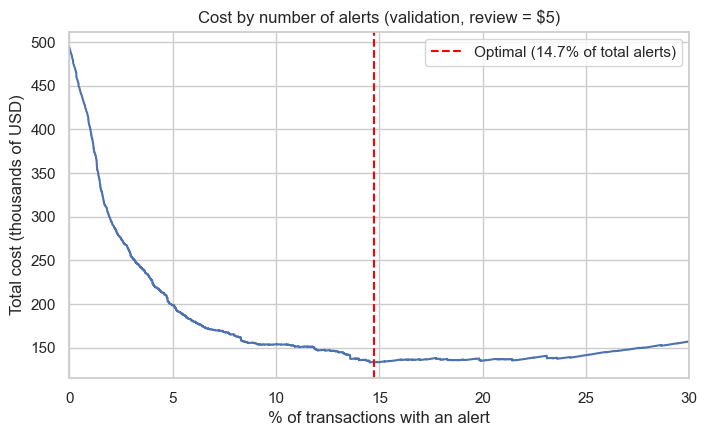

In [4]:
REVIEW_COST = 5.0   # assumption: cost of reviewing one alert (USD). It is varied in section 4.

curve = cost_curve(y_valid, p_valid, amt_valid, REVIEW_COST)
curve["alerts_%"] = 100 * curve["n_flagged"] / len(valid)
best = curve.loc[curve["cost"].idxmin()]
thr = best["threshold"]
print(f"Optimal threshold: {thr:.4f}  |  alerts: {best['alerts_%']:.2f}% of total transactions  |  cost: ${best['cost']:,.0f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve["alerts_%"], curve["cost"] / 1e3)
ax.axvline(best["alerts_%"], color="red", linestyle="--", label=f"Optimal ({best['alerts_%']:.1f}% of total alerts)")
ax.set_xlim(0, 30)
ax.set_xlabel("% of transactions with an alert"); ax.set_ylabel("Total cost (thousands of USD)")
ax.set_title(f"Cost by number of alerts (validation, review = ${REVIEW_COST:.0f})")
plt.savefig("../reports/figures/cost_curve.png", dpi=150, bbox_inches="tight")
ax.legend(); plt.show()

## 3. Final evaluation on test
The threshold chosen on validation is applied to test **without changes**. It is compared against:
- **No model:** nothing is reviewed, all frauds are lost.
- **Review everything:** every transaction is reviewed.
- **0.5 threshold:** the naive rule.

In [5]:
rows = {
    "validation (optimal threshold)": cost_at_threshold(y_valid, p_valid, amt_valid, REVIEW_COST, thr),
    "test (validation threshold)": cost_at_threshold(y_test, p_test, amt_test, REVIEW_COST, thr),
    "test (0,5 threshold)": cost_at_threshold(y_test, p_test, amt_test, REVIEW_COST, 0.5),
}
res = pd.DataFrame(rows).T
res.round(4)

,threshold,alerts_%,precision,recall,cost,cost_no_model,cost_review_all,savings_vs_no_model_%
validation (optimal threshold),0.0217,14.7334,0.1965,0.8336,133161.8549,493820.5910,426515.0,73.0344
test (validation threshold),0.0217,15.7308,0.1767,0.8013,167984.9766,495244.3967,473180.0,66.0804
"test (0,5 threshold)",0.5000,1.4297,0.8189,0.3376,390276.7297,495244.3967,473180.0,21.1951


In [6]:
# Métricas estadísticas finales en test (primera y única vez)
pd.Series(evaluate(y_test, p_test)).round(4)

auc_pr           0.5441
auc_roc          0.9062
tasa_base        0.0347
recall@prec50    0.5168
recall@prec80    0.3525
dtype: float64

## 4. Sensitivity to review cost
For each review cost, the threshold is chosen on **validation** and evaluated on **test**.

In [7]:
rows = []
for rc in [1, 2, 5, 10, 25, 50, 100]:
    t = best_threshold(y_valid, p_valid, amt_valid, rc)
    r = cost_at_threshold(y_test, p_test, amt_test, rc, t)
    rows.append({"review_cost": rc, **{k: r[k] for k in ["threshold", "alerts_%", "precision", "recall", "cost", "cost_no_model", "savings_vs_no_model_%"]}})
sens = pd.DataFrame(rows).set_index("review_cost")
sens.round(3)

,threshold,alerts_%,precision,recall,cost,cost_no_model,savings_vs_no_model_%
review_cost,,,,,,,
1,0.006,44.254,0.074,0.939,62154.552,495244.397,87.450
2,0.012,25.096,0.121,0.873,102178.218,495244.397,79.368
5,0.022,15.731,0.177,0.801,167984.977,495244.397,66.080
10,0.040,9.431,0.261,0.710,235460.665,495244.397,52.456
25,0.073,5.798,0.368,0.615,338801.935,495244.397,31.589
50,0.158,3.119,0.551,0.496,422576.274,495244.397,14.673
100,0.399,1.660,0.777,0.372,523609.157,495244.397,-5.727


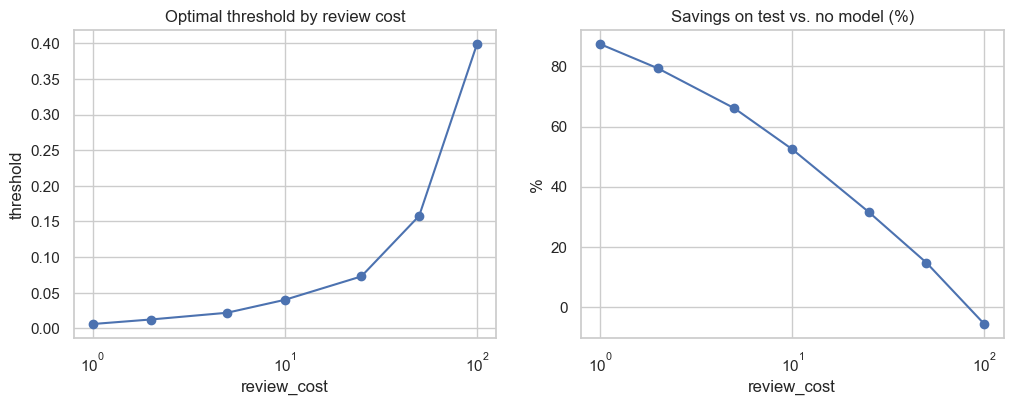

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sens["threshold"].replace(np.inf, np.nan).plot(marker="o", ax=ax[0], logx=True, title="Optimal threshold by review cost")
ax[0].set_ylabel("threshold")
sens["savings_vs_no_model_%"].plot(marker="o", ax=ax[1], logx=True, title="Savings on test vs. no model (%)")
ax[1].set_ylabel("%")
plt.savefig("../reports/figures/sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Interpretability with SHAP
SHAP values (contributions to the fraud log-odds) are calculated on a sample of 10,000 validation transactions, using LightGBM's native computation (`pred_contrib`).

**Note:** many features are masked (`V1`-`V339`, `id_*`), so we can say *how much* they weigh but not *what they represent*.

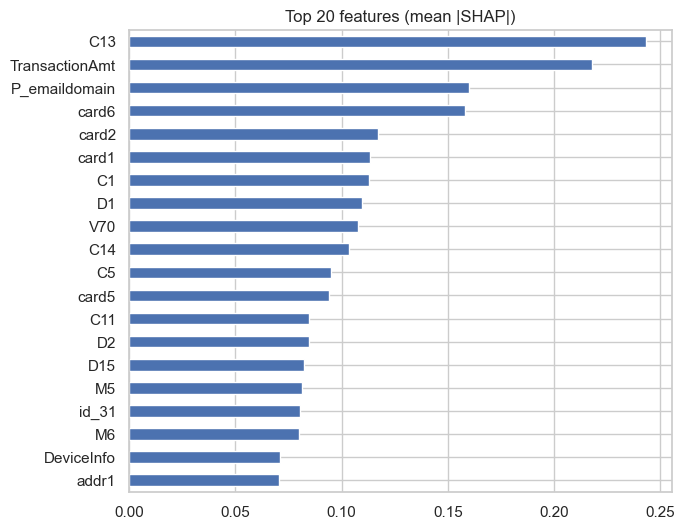

Masked features (V*, id_*) in the top 20: 2 de 20
Weight of the masked features over the total |SHAP|: 38.7%


In [10]:
sample = valid.sample(10000, random_state=0)
Xs = sample[features]

contrib = model.booster_.predict(Xs, pred_contrib=True)   # (n, n_features + 1)
sv, base = contrib[:, :-1], contrib[:, -1]

# versión numérica de X solo para graficar (las categóricas pasan a sus códigos)
Xplot = Xs.copy()
for c in Xplot.columns:
    if isinstance(Xplot[c].dtype, pd.CategoricalDtype):
        codes = Xplot[c].cat.codes
        Xplot[c] = codes.where(codes >= 0).astype("float32")

imp = pd.Series(np.abs(sv).mean(axis=0), index=features).sort_values(ascending=False)
imp.head(20).iloc[::-1].plot(kind="barh", figsize=(7, 6), title="Top 20 features (mean |SHAP|)")
plt.show()

is_masked = imp.index.str.match(r"^(V\d+|id_\d+)$")
print(f"Masked features (V*, id_*) in the top 20: {is_masked[:20].sum()} de 20")
print(f"Weight of the masked features over the total |SHAP|: {100 * imp[is_masked].sum() / imp.sum():.1f}%")

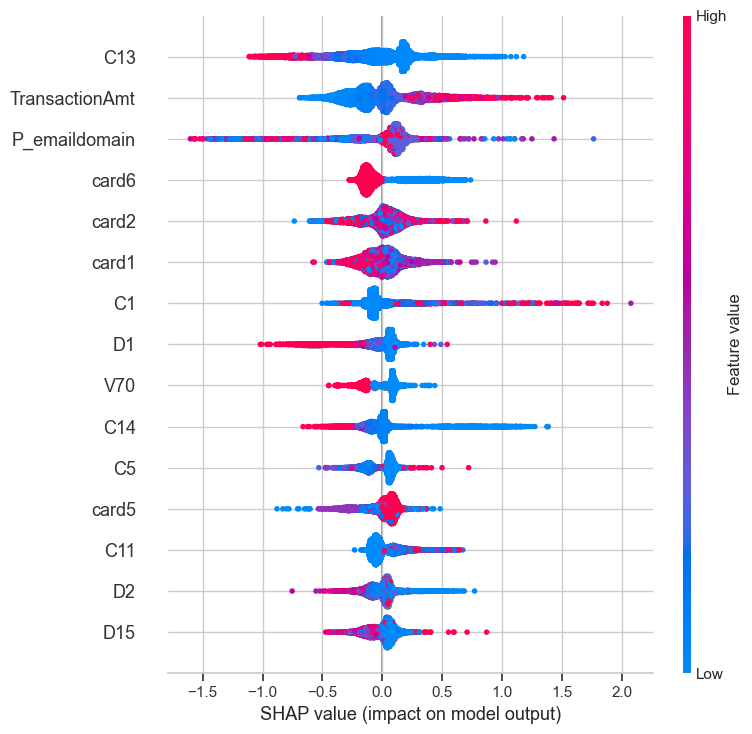

In [11]:
shap.summary_plot(sv, Xplot, max_display=15, show=False)
plt.savefig("../reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

### An individual prediction
Explanation of a real fraud with a high score from the sample (values in log-odds).

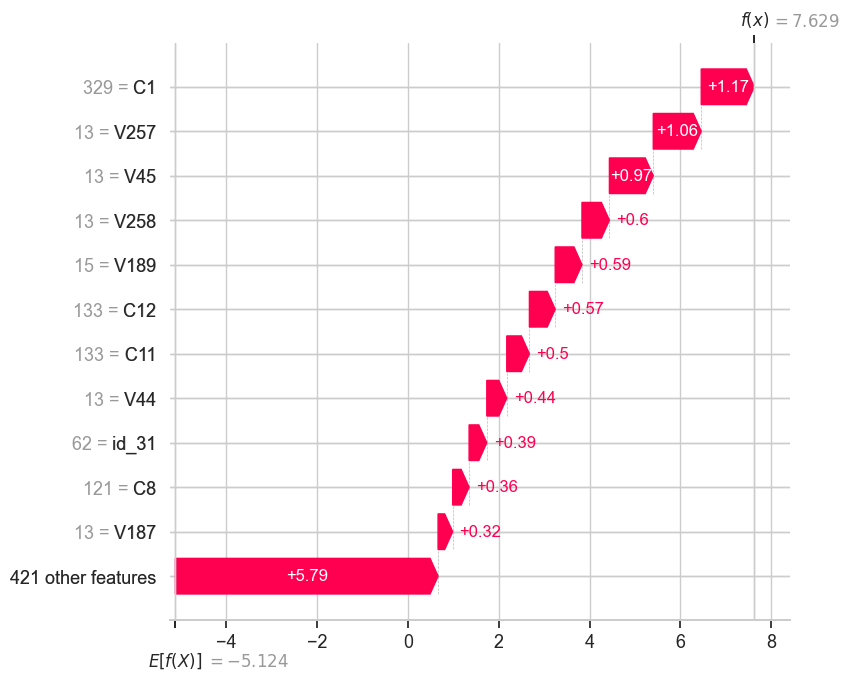

In [12]:
scores = model.predict_proba(Xs)[:, 1]
idx = int(np.argmax(np.where(sample["isFraud"].values == 1, scores, -1)))
exp = shap.Explanation(values=sv[idx], base_values=base[idx], data=Xplot.iloc[idx].values, feature_names=features)
shap.plots.waterfall(exp, max_display=12)

## 6. Conclusions

**Final result on test:** PR-AUC 0.544 (15.7x the base rate), ROC-AUC 0.906, recall at precision ≥50% of 0.517 and at ≥80% of 0.353. This is lower than validation (PR-AUC 0.617, baseline average over 3 seeds). Probable cause: temporal drift (test is the segment furthest from train) and some optimism in validation, which was used for early stopping and the threshold (unverified hypothesis).

**Cost (review = 5 USD):** the optimal threshold on validation (0.0217) generates alerts on ~15% of transactions. On test it achieves savings of 66% compared to having no model (168 thousand vs 495 thousand USD), with 80% recall and 17.7% precision. The 0.5 threshold only saves 21%: it detects 34% of frauds.

**Sensitivity:** the model's value depends on the review cost. With 1 USD the savings are 87%; with 50 USD, 15%; with 100 USD they are negative (-5.7%): the validation threshold did not transfer well to test and the model cost more than doing nothing.

**Interpretability (SHAP):** among the most influential features are `P_emaildomain` (third), `C13`, `TransactionAmt`, and `card6`; `C1` also appears in the top 20. High amounts push toward fraud; high values of `C13` push toward non-fraud. For `P_emaildomain` the colors are mixed: its effect depends on the domain and does not follow a single direction. The masked features (`V*`, `id_*`) weigh little individually (2 of the top 20) but add up to 38.7% of the total |SHAP|, which limits interpretability. SHAP describes what the model uses, not what causes fraud.
- `card6`: credit card transactions push toward fraud and debit card ones toward non-fraud, which matches the observed rates (6.7% vs 2.4%).

**Limitations:** own cost assumptions (fixed and perfect review, loss = amount); no chargebacks or friction; a single temporal split; model trained only on train; test result with a single seed; hyperparameters not tuned.